Import necessary pacakages and read data

In [27]:
import geopandas as gpd
import pandas as pd

# change this as needed (i don't know why it doesn't take relative paths and I'm too tired to look into it).
species = "dromedaries"
file_path = f"c:\\Users\\vladu\\OneDrive\\Desktop\\geotracking_camelids_NINO_project\\map_project\\camel_data\\{species}.shp"

data = gpd.read_file(file_path)


View a sample

In [28]:
data.head()


,id,species_or,species_re,hybrid?,other_name,domestic_s,evidence_t,primary_so,NISP_.,NISP_%,direct_rad,date_old,date_young,date_other,site,comments,lat,long,crs,geometry
0,16.0,Camelus dromedarius,Camelus dromedarius,NaN,None,NaN,faunal remains,NaN,NaN,NaN,0.0,-2600.0,-2000.0,BA,Umm an-Nar,NaN,24.438298,54.514455,EPSG:4326,POINT (4999243.267 3091625.276)
1,17.0,Camelus dromedarius,Camelus dromedarius,NaN,None,NaN,faunal remains,NaN,NaN,NaN,0.0,-2600.0,-2000.0,BA,Ras Ghanada,site is a gulf. Where did they find the remains?,NaN,NaN,NaN,None
2,19.0,Camelus dromedarius,Camelus dromedarius,NaN,None,NaN,faunal remains,NaN,NaN,NaN,0.0,-2700.0,-2000.0,NaN,Harappa,remains could be intrusive in the stratigraphy...,30.628891,72.863890,EPSG:4326,POINT (6513757.227 3839225.313)
3,24.0,Camelus dromedarius,Camelus dromedarius,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Anau,NaN,37.883282,58.533263,EPSG:4326,POINT (5037873.507 4682833.896)
4,54.0,Camelus dromedarius,Camelus dromedarius,NaN,None,domestic,faunal remains,NaN,1.0,0.01%,NaN,1600.0,1799.0,17th-18th centuries CE,Agighiol,"2 specimens radiocarbon dated, but they don't ...",45.035168,28.875651,EPSG:4326,POINT (2372415.811 5470616.804)


View graphical

<Axes: >

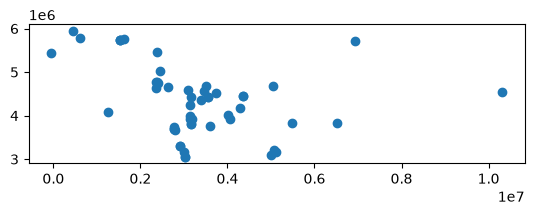

In [29]:
data.plot()


Determine filter for additive selection (keep adding to selection based on new filter element). Also export the filter vector as csv if I want to join it to another shapefile later.

In [30]:
# Pick which column becomes the filter.
filter_column = "date_old"
# Then make and sort the filter.
filter_vector = sorted(data[filter_column].unique())
filter_dataframe = {
  'int_id' : range(1, len(filter_vector) + 1),
  'filter_vector' : filter_vector
}

df = pd.DataFrame(filter_dataframe)
df
df.to_csv(
    rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\camel_data\{species}_years.csv"
)

Initialise output with the same structure as input and initialise a counter to use in file naming

In [31]:
output = data.iloc[0:0]  # empty dataframe with same columns

counter = 1


Then just loop over elements in the filter and keep adding and saving the current output from each iteration

In [32]:
for item in filter_vector:
    tmp = data[data[filter_column] == item]

    output = pd.concat([output, tmp], ignore_index=True)
    output = gpd.GeoDataFrame(output, geometry="geometry", crs=data.crs)

    output.to_file(
        rf"c:\Users\vladu\OneDrive\Desktop\geotracking_camelids_NINO_project\map_project\camel_data\{species}_{counter}.shp",
        driver="ESRI Shapefile",
    )

    counter += 1